# Predicción de cancelaciones de reservas hoteleras
## Notebook 03 · Reducción de dimensión (Sección V)

**Modelos y Simulación de Sistemas II – Universidad de Antioquia**
Juan Camilo Morales Villada · Juan Sebastián Andraus López · Jose Miguel Fajardo Fernández

Este notebook reproduce la Sección V del informe: el análisis individual de las variables, la extracción lineal de
características con PCA y la extracción no lineal con UMAP, aplicadas a los dos mejores modelos de la Sección IV
(guardados por el notebook 02 en `resultados/mejores_modelos.json`). En cada nuevo espacio de características se
vuelven a ajustar los hiperparámetros.

**Tiempo de ejecución aproximado:** 30 a 50 minutos en Google Colab (CPU). Requiere haber ejecutado antes el notebook 02.

## 1. Configuración

In [1]:
# Solo en Google Colab: descarga el repositorio y se ubica en la carpeta notebooks/
import os, subprocess, sys
REPO = "https://github.com/Moraa0711/ModelosII-Proyecto-HotelBooking.git"
if "google.colab" in sys.modules:
    destino = "/content/ModelosII-Proyecto-HotelBooking"
    if not os.path.exists(destino):
        subprocess.run(["git", "clone", "-q", REPO, destino], check=True)
    os.chdir(os.path.join(destino, "notebooks"))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "umap-learn"], check=True)

In [2]:
import ast
import itertools
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from xgboost import XGBClassifier
import umap

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(RAIZ))
from src import preprocesamiento as pp
from src import evaluacion as ev

RUTA_FIGURAS = RAIZ / "figuras"
RUTA_RESULTADOS = RAIZ / "resultados"
SEMILLA = ev.SEMILLA
warnings.filterwarnings("ignore")
plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.spines.top": False,
                     "axes.spines.right": False})
from matplotlib.ticker import FuncFormatter
coma = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))
ARCHIVO = {"Regresión logística": "regresion_logistica", "KNN": "knn", "Random Forest": "random_forest",
           "XGBoost": "xgboost", "Red neuronal (MLP)": "mlp", "SVM (RBF)": "svm"}
print("umap-learn", umap.__version__)

umap-learn 0.5.12


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
datos, _ = pp.limpiar_datos(pp.cargar_datos(RAIZ / "data" / "hotel_booking.csv"))
X, y = pp.separar_xy(datos)
grupos = pp.grupos_repetidos(datos)

# Misma partición y misma muestra del notebook 02
idx_ent, idx_pru = ev.particion_prueba(X, y, grupos)
X_ent, y_ent, g_ent = X.iloc[idx_ent], y[idx_ent], grupos[idx_ent]
X_pru, y_pru = X.iloc[idx_pru], y[idx_pru]
idx_muestra = ev.muestra_agrupada(y_ent, g_ent, n=15000)

with open(RUTA_RESULTADOS / "mejores_modelos.json", encoding="utf-8") as f:
    mejores = json.load(f)
resumen_iv = pd.read_csv(RUTA_RESULTADOS / "resumen_modelos.csv")
TOP2 = list(mejores)
print("Modelos evaluados en esta sección:", TOP2)

Modelos evaluados en esta sección: ['XGBoost', 'Random Forest']


In [4]:
# Estimadores y mallas reducidas para volver a ajustar los hiperparámetros en cada espacio
neg, pos = np.bincount(y_ent)
fabrica = {
    "Regresión logística": (LogisticRegression(max_iter=3000, class_weight="balanced"),
                            {"clf__C": [0.01, 0.1, 1, 10]}),
    "KNN": (KNeighborsClassifier(), {"clf__n_neighbors": [5, 11, 21, 41], "clf__weights": ["uniform", "distance"]}),
    "Random Forest": (RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=SEMILLA),
                      {"clf__max_depth": [10, 20, None], "clf__min_samples_leaf": [1, 5]}),
    "XGBoost": (XGBClassifier(n_estimators=400, tree_method="hist", scale_pos_weight=neg / pos, eval_metric="logloss",
                              n_jobs=-1, random_state=SEMILLA),
                {"clf__max_depth": [3, 6, 9], "clf__learning_rate": [0.1, 0.3]}),
    "Red neuronal (MLP)": (MLPClassifier(early_stopping=True, max_iter=300, random_state=SEMILLA),
                           {"clf__hidden_layer_sizes": [(64,), (128, 64)], "clf__alpha": [0.0001, 0.01]}),
    "SVM (RBF)": (SVC(kernel="rbf", class_weight="balanced"), {"clf__C": [1, 10], "clf__gamma": ["scale", 0.03, 0.3]}),
}
N_JOBS_BUSQUEDA = {"Random Forest": 1, "XGBoost": 1}

def datos_ajuste(nombre):
    if mejores[nombre]["muestra"]:
        return X_ent.iloc[idx_muestra], y_ent[idx_muestra], g_ent[idx_muestra]
    return X_ent, y_ent, g_ent

def a_valor(texto):
    # Convierte el texto guardado de un hiperparámetro ('None', '(64,)', '0.1', 'scale') a su valor
    try:
        return ast.literal_eval(texto)
    except (ValueError, SyntaxError):
        return texto

def parametros_iv(nombre):
    return {k: (tuple(v) if isinstance(v, list) else v) for k, v in mejores[nombre]["parametros"].items()}

## 2. Análisis individual de variables (Sección V-A)
Se calcula, **solo con el conjunto de entrenamiento**, qué tanta información aporta cada una de las 28 variables de
entrada por sí sola para separar las clases:
- **Información mutua** con `is_canceled` (sirve para variables numéricas y categóricas).
- Variables numéricas y binarias: **correlación** con la variable objetivo e **índice de discriminación de Fisher**,
  $J = (\mu_1-\mu_0)^2 / (\sigma_1^2+\sigma_0^2)$, donde $\mu_c$ y $\sigma_c^2$ son la media y la varianza en cada clase.
- Variables categóricas: **V de Cramér** con la variable objetivo.

También se revisa la **redundancia**: pares de variables muy correlacionadas entre sí.

In [5]:
ent = datos.iloc[idx_ent]
num_bin = pp.NUMERICAS + pp.TEMPORALES + pp.BINARIAS
categ = pp.NOMINALES + pp.PAIS

def cramer_v(a, b):
    tabla = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(tabla, correction=False)[0]
    n = tabla.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

def fisher(x, yy):
    x0, x1 = x[yy == 0], x[yy == 1]
    return (x1.mean() - x0.mean()) ** 2 / (x1.var() + x0.var())

# Información mutua: las categóricas se pasan como códigos enteros marcados como discretos
Xmi = ent[num_bin + categ].copy()
for c in categ:
    Xmi[c] = Xmi[c].astype("category").cat.codes
discretas = [c in categ or c in pp.BINARIAS for c in Xmi.columns]
mi = mutual_info_classif(Xmi, ent[pp.OBJETIVO], discrete_features=discretas, random_state=SEMILLA)

filas = []
for c, valor_mi in zip(Xmi.columns, mi):
    fila = {"Variable": c, "Tipo": "Categórica" if c in categ else ("Binaria" if c in pp.BINARIAS else "Numérica"),
            "Información mutua": valor_mi}
    if c in categ:
        fila["V de Cramér"] = cramer_v(ent[c], ent[pp.OBJETIVO])
    else:
        fila["Correlación"] = ent[c].corr(ent[pp.OBJETIVO])
        fila["Índice de Fisher"] = fisher(ent[c], ent[pp.OBJETIVO])
    filas.append(fila)
individual = pd.DataFrame(filas).sort_values("Información mutua", ascending=False).reset_index(drop=True)
individual.to_csv(RUTA_RESULTADOS / "analisis_individual.csv", index=False)
individual.round(4)

,Variable,Tipo,Información mutua,Correlación,Índice de Fisher,V de Cramér
0,deposit_type,Categórica,0.1310,NaN,NaN,0.4813
1,lead_time,Numérica,0.0832,0.2908,0.1848,NaN
2,adr,Numérica,0.0819,0.0452,0.0045,NaN
3,country,Categórica,0.0670,NaN,NaN,0.3606
4,previous_cancellations,Numérica,0.0454,0.1104,0.0201,NaN
5,total_of_special_requests,Numérica,0.0386,-0.2346,0.1329,NaN
6,market_segment,Categórica,0.0380,NaN,NaN,0.2715
7,required_car_parking_spaces,Numérica,0.0310,-0.1944,0.1060,NaN
8,booking_changes,Numérica,0.0183,-0.1461,0.0520,NaN
9,distribution_channel,Categórica,0.0175,NaN,NaN,0.1786


In [6]:
# Redundancia entre variables numéricas (|r| > 0,8) y entre categóricas (V de Cramér > 0,8)
corr = ent[pp.NUMERICAS + pp.TEMPORALES].corr()
pares = [(a, b, corr.loc[a, b]) for a, b in itertools.combinations(corr.columns, 2) if abs(corr.loc[a, b]) > 0.8]
pares += [(a, b, cramer_v(ent[a], ent[b])) for a, b in itertools.combinations(pp.NOMINALES, 2)
          if cramer_v(ent[a], ent[b]) > 0.8]
pd.DataFrame(pares, columns=["Variable 1", "Variable 2", "Asociación"]).round(3)

,Variable 1,Variable 2,Asociación
0,arrival_date_month,arrival_date_week_number,0.995


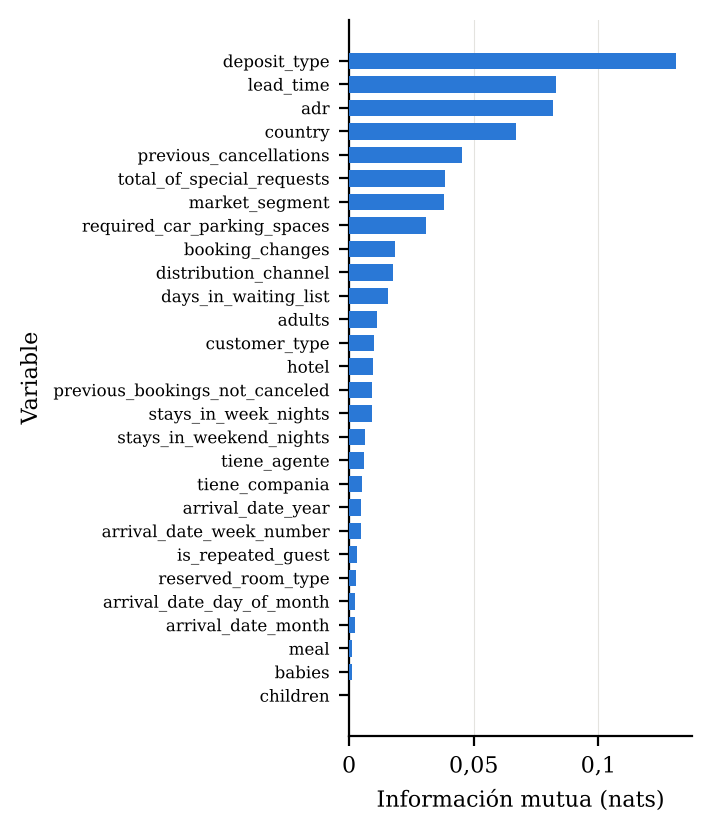

In [7]:
# Fig. 4 del informe: información mutua de cada variable
fig, ax = plt.subplots(figsize=(3.6, 4.2))
orden = individual.sort_values("Información mutua")
ax.barh(orden["Variable"], orden["Información mutua"], color="#2a78d6", height=0.7, zorder=3)
ax.set_xlabel("Información mutua (nats)")
ax.set_ylabel("Variable")
ax.tick_params(axis="y", labelsize=6)
ax.grid(axis="x", lw=0.4, color="#e4e3df", zorder=0)
ax.xaxis.set_major_formatter(coma)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "fig4_informacion_mutua.png", dpi=300)
plt.show()

In [8]:
# Variables candidatas a eliminar: aporte individual casi nulo (información mutua < 0,005) o redundantes
UMBRAL_MI = 0.005
candidatas = list(individual.loc[individual["Información mutua"] < UMBRAL_MI, "Variable"])
redundantes = [b for a, b, _ in pares if b not in candidatas]
candidatas += redundantes
print("Candidatas a eliminar:", candidatas)

Candidatas a eliminar: ['arrival_date_year', 'arrival_date_week_number', 'is_repeated_guest', 'reserved_room_type', 'arrival_date_day_of_month', 'arrival_date_month', 'meal', 'babies', 'children']


In [9]:
# ¿Qué pasa si se eliminan? Validación cruzada del mejor modelo con y sin las candidatas
mejor = TOP2[0]
est, _ = fabrica[mejor]
Xm, ym, gm = datos_ajuste(mejor)
resultado_sel = []
for etiqueta, quitar in [("Todas las variables", []), ("Sin candidatas", candidatas)]:
    cols = [c for c in pp.columnas_entrada() if c not in quitar]
    prep = pp.construir_preprocesador()
    prep.transformers = [(n, t, [c for c in cs if c in cols]) for n, t, cs in prep.transformers]
    pipe = Pipeline([("prep", prep), ("clf", clone(est))]).set_params(**parametros_iv(mejor))
    cv = cross_validate(pipe, Xm[cols], ym, groups=gm, cv=ev.validacion_cruzada(), scoring=ev.METRICAS,
                        n_jobs=N_JOBS_BUSQUEDA.get(mejor, -1))
    f1m, f1ic = ev.intervalo_confianza(cv["test_f1"]); aucm, aucic = ev.intervalo_confianza(cv["test_roc_auc"])
    resultado_sel.append({"Modelo": mejor, "Conjunto": etiqueta, "Variables de entrada": len(cols),
                          "F1 valid.": ev.fmt(f1m, f1ic), "AUC-ROC valid.": ev.fmt(aucm, aucic)})
seleccion = pd.DataFrame(resultado_sel)
seleccion.to_csv(RUTA_RESULTADOS / "seleccion_variables.csv", index=False)
seleccion

,Modelo,Conjunto,Variables de entrada,F1 valid.,AUC-ROC valid.
0,XGBoost,Todas las variables,28,"0,811 ± 0,011","0,938 ± 0,004"
1,XGBoost,Sin candidatas,19,"0,790 ± 0,013","0,926 ± 0,005"


## 3. Extracción lineal de características: PCA (Sección V-B)
PCA se aplica sobre las variables ya codificadas (One-Hot y numéricas estandarizadas). **Criterio:** se conserva el menor
número de componentes que explica al menos el **95 % de la varianza** del conjunto de entrenamiento.

In [10]:
prep_pca = pp.construir_preprocesador().fit(X_ent)
Z_ent = prep_pca.transform(X_ent)
pca_total = PCA(random_state=SEMILLA).fit(Z_ent)
var_acum = np.cumsum(pca_total.explained_variance_ratio_)
D_ORIGINAL = Z_ent.shape[1]
N_PCA = int(np.searchsorted(var_acum, 0.95) + 1)
print(f"Variables codificadas: {D_ORIGINAL} | componentes para el 95 % de la varianza: {N_PCA} "
      f"(reducción de {(1 - N_PCA / D_ORIGINAL) * 100:.1f} %)")
print("Componentes para 80 / 90 / 99 %:", [int(np.searchsorted(var_acum, q) + 1) for q in (0.8, 0.9, 0.99)])

Variables codificadas: 90 | componentes para el 95 % de la varianza: 25 (reducción de 72.2 %)
Componentes para 80 / 90 / 99 %: [15, 20, 44]


In [11]:
# Nuevo ajuste de hiperparámetros de los dos mejores modelos en el espacio PCA
busq_pca, res_pca = {}, {}
for nombre in TOP2:
    inicio = time.time()
    est, malla = fabrica[nombre]
    Xm, ym, gm = datos_ajuste(nombre)
    pipe = Pipeline([("prep", pp.construir_preprocesador()), ("pca", PCA(n_components=N_PCA, random_state=SEMILLA)),
                     ("clf", clone(est))])
    b = GridSearchCV(pipe, malla, scoring=ev.METRICAS, refit=ev.METRICA_PRINCIPAL, cv=ev.validacion_cruzada(),
                     return_train_score=True, n_jobs=N_JOBS_BUSQUEDA.get(nombre, -1))
    b.fit(Xm, ym, groups=gm)
    busq_pca[nombre] = b
    t = ev.tabla_busqueda(b, list(malla))
    t.to_csv(RUTA_RESULTADOS / f"pca_busqueda_{ARCHIVO[nombre]}.csv", index=False)
    res_pca[nombre] = {"tabla": t, "prueba": ev.metricas_prueba(b.best_estimator_, X_pru, y_pru),
                       "tiempo": time.time() - inicio}
    print(f"{nombre:22s} {res_pca[nombre]['tiempo']:5.0f} s | F1 val {ev.fmt(t.iloc[0]['f1_val'], t.iloc[0]['f1_val_ic'])} "
          f"| {b.best_params_}")

XGBoost                  126 s | F1 val 0,785 ± 0,007 | {'clf__learning_rate': 0.1, 'clf__max_depth': 6}


Random Forest            834 s | F1 val 0,777 ± 0,006 | {'clf__max_depth': None, 'clf__min_samples_leaf': 5}


In [12]:
# Desempeño del mejor modelo según el número de componentes (con sus hiperparámetros de la Sección IV)
mejor = TOP2[0]
est, _ = fabrica[mejor]
Xm, ym, gm = datos_ajuste(mejor)
curva_pca = []
for n in [2, 5, 10, 15, 20, N_PCA, 40, 60]:
    pipe = Pipeline([("prep", pp.construir_preprocesador()), ("pca", PCA(n_components=n, random_state=SEMILLA)),
                     ("clf", clone(est))]).set_params(**parametros_iv(mejor))
    cv = cross_validate(pipe, Xm, ym, groups=gm, cv=ev.validacion_cruzada(), scoring={"f1": "f1"},
                        n_jobs=N_JOBS_BUSQUEDA.get(mejor, -1))
    m, ic = ev.intervalo_confianza(cv["test_f1"])
    curva_pca.append({"componentes": n, "f1_val": m, "f1_val_ic": ic})
curva_pca = pd.DataFrame(curva_pca).drop_duplicates("componentes").sort_values("componentes")
curva_pca.round(4)

,componentes,f1_val,f1_val_ic
0,2,0.3519,0.0332
1,5,0.6035,0.0126
2,10,0.6986,0.0069
3,15,0.7170,0.0105
4,20,0.7705,0.0080
5,25,0.7814,0.0093
6,40,0.7892,0.0065
7,60,0.7877,0.0082


## 4. Extracción no lineal de características: UMAP (Sección V-C)
UMAP se ajusta sobre las variables codificadas. Por su costo computacional se trabaja con la **misma muestra de
15.000 reservas** usada para KNN y SVM. **Criterio:** el número de componentes (2, 5, 10 o 20) y los hiperparámetros
del clasificador se escogen por el F1 de validación cruzada. Para que la comparación sea justa, cada modelo también se
evalúa en el espacio original con esa misma muestra.

Para no repetir el ajuste de UMAP por cada combinación de hiperparámetros, en cada pliegue se ajusta UMAP una sola vez
por número de componentes (con los datos de entrenamiento del pliegue) y sobre esa proyección se prueban todas las
combinaciones del clasificador.

**Nota sobre la reproducibilidad:** UMAP usa una búsqueda aproximada de vecinos y una optimización estocástica. Aunque se fija `random_state`, los resultados pueden variar ligeramente entre ejecuciones o equipos (del orden de ±0,01 en el F1). Las conclusiones de esta sección no cambian con esa variación.

In [13]:
COMPONENTES_UMAP = [2, 5, 10, 20]
Xs, ys, gs = X_ent.iloc[idx_muestra], y_ent[idx_muestra], g_ent[idx_muestra]
pliegues = list(ev.validacion_cruzada().split(Xs, ys, gs))
registros = []
inicio = time.time()
for f, (tr, va) in enumerate(pliegues):
    prep = pp.construir_preprocesador().fit(Xs.iloc[tr])
    Z_tr, Z_va = prep.transform(Xs.iloc[tr]), prep.transform(Xs.iloc[va])
    espacios = {"Original": (Z_tr, Z_va)}
    for n in COMPONENTES_UMAP:
        red = umap.UMAP(n_components=n, n_neighbors=15, min_dist=0.1, random_state=SEMILLA).fit(Z_tr)
        espacios[n] = (red.embedding_, red.transform(Z_va))
    for nombre in TOP2:
        est, malla = fabrica[nombre]
        claves = list(malla)
        for combinacion in itertools.product(*malla.values()):
            params = {k.replace("clf__", ""): v for k, v in zip(claves, combinacion)}
            for espacio, (E_tr, E_va) in espacios.items():
                clf = clone(est).set_params(**params).fit(E_tr, ys[tr])
                registros.append({
                    "modelo": nombre, "espacio": espacio, "pliegue": f, **{k: str(v) for k, v in params.items()},
                    "f1_val": f1_score(ys[va], clf.predict(E_va)),
                    "auc_val": roc_auc_score(ys[va], ev.puntajes(clf, E_va)),
                    "f1_ent": f1_score(ys[tr], clf.predict(E_tr)),
                })
    print(f"Pliegue {f + 1}/5 listo ({time.time() - inicio:.0f} s)")
umap_cv = pd.DataFrame(registros)
umap_cv.to_csv(RUTA_RESULTADOS / "umap_validacion_pliegues.csv", index=False)

Pliegue 1/5 listo (158 s)


Pliegue 2/5 listo (289 s)


Pliegue 3/5 listo (423 s)


Pliegue 4/5 listo (558 s)


Pliegue 5/5 listo (694 s)


In [14]:
# Media e IC95 % por modelo, espacio y combinación de hiperparámetros
def resumir(df):
    filas = []
    columnas_param = [c for c in df.columns if c not in ("modelo", "espacio", "pliegue", "f1_val", "auc_val", "f1_ent")]
    for clave, g in df.groupby(["modelo", "espacio"] + columnas_param, dropna=False):
        fila = dict(zip(["modelo", "espacio"] + columnas_param, clave))
        for m in ["f1_val", "auc_val", "f1_ent"]:
            fila[m], fila[m + "_ic"] = ev.intervalo_confianza(g[m])
        filas.append(fila)
    return pd.DataFrame(filas)

umap_res = resumir(umap_cv)
mejor_por_espacio = (umap_res.sort_values("f1_val", ascending=False)
                     .groupby(["modelo", "espacio"], sort=False).head(1)
                     .sort_values(["modelo", "f1_val"], ascending=[True, False]))
mejor_por_espacio.dropna(axis=1, how="all").round(4)

,modelo,espacio,max_depth,learning_rate,min_samples_leaf,f1_val,f1_val_ic,auc_val,auc_val_ic,f1_ent,f1_ent_ic
26,Random Forest,Original,20,NaN,1,0.7755,0.0170,0.9137,0.0098,0.9615,0.0022
20,Random Forest,20,20,NaN,1,0.6332,0.0215,0.7870,0.0182,0.9746,0.0088
17,Random Forest,10,None,NaN,5,0.6291,0.0271,0.7859,0.0230,0.9222,0.0046
9,Random Forest,5,20,NaN,5,0.6105,0.0327,0.7707,0.0373,0.8780,0.0032
3,Random Forest,2,20,NaN,5,0.5865,0.0369,0.7422,0.0381,0.8376,0.0109
56,XGBoost,Original,6,0.1,NaN,0.7774,0.0090,0.9136,0.0078,0.9440,0.0022
44,XGBoost,10,6,0.1,NaN,0.6323,0.0152,0.7797,0.0183,0.9274,0.0043
49,XGBoost,20,3,0.3,NaN,0.6242,0.0239,0.7780,0.0250,0.8546,0.0062
36,XGBoost,5,3,0.1,NaN,0.5981,0.0445,0.7577,0.0440,0.7291,0.0092
31,XGBoost,2,3,0.3,NaN,0.5856,0.0321,0.7424,0.0324,0.7420,0.0065


In [15]:
# Número de componentes escogido y evaluación en prueba (UMAP ajustado con toda la muestra)
res_umap = {}
for nombre in TOP2:
    est, malla = fabrica[nombre]
    filas_m = mejor_por_espacio[(mejor_por_espacio["modelo"] == nombre) & (mejor_por_espacio["espacio"] != "Original")]
    elegido = filas_m.iloc[0]
    n = int(elegido["espacio"])
    params = {k.replace("clf__", ""): a_valor(elegido[k.replace("clf__", "")]) for k in malla}
    prep = pp.construir_preprocesador().fit(Xs)
    red = umap.UMAP(n_components=n, n_neighbors=15, min_dist=0.1, random_state=SEMILLA).fit(prep.transform(Xs))
    clf = clone(est).set_params(**params).fit(red.embedding_, ys)
    E_pru = red.transform(prep.transform(X_pru))
    pred = clf.predict(E_pru)
    res_umap[nombre] = {"n": n, "params": params, "fila": elegido,
                        "prueba": {"f1": f1_score(y_pru, pred), "roc_auc": roc_auc_score(y_pru, ev.puntajes(clf, E_pru))},
                        "dim_original": prep.transform(Xs.iloc[:5]).shape[1]}
    # Línea base en el espacio original con la misma muestra
    base = mejor_por_espacio[(mejor_por_espacio["modelo"] == nombre) & (mejor_por_espacio["espacio"] == "Original")].iloc[0]
    params_b = {k.replace("clf__", ""): a_valor(base[k.replace("clf__", "")]) for k in malla}
    clf_b = clone(est).set_params(**params_b).fit(prep.transform(Xs), ys)
    Z_pru = prep.transform(X_pru)
    res_umap[nombre]["base"] = {"fila": base, "params": params_b,
                                "prueba": {"f1": f1_score(y_pru, clf_b.predict(Z_pru)),
                                           "roc_auc": roc_auc_score(y_pru, ev.puntajes(clf_b, Z_pru))}}
    print(f"{nombre}: UMAP con {n} componentes, {params} -> F1 prueba {res_umap[nombre]['prueba']['f1']:.4f}")

XGBoost: UMAP con 10 componentes, {'max_depth': 6, 'learning_rate': 0.1} -> F1 prueba 0.6222


Random Forest: UMAP con 20 componentes, {'max_depth': 20, 'min_samples_leaf': 1} -> F1 prueba 0.6433


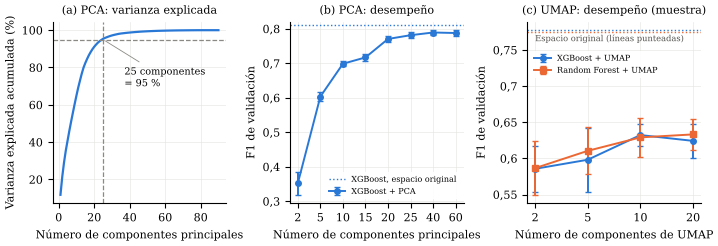

In [16]:
# Fig. 5 del informe: (a) varianza acumulada de PCA; (b) F1 según el número de componentes de PCA;
# (c) F1 según el número de componentes de UMAP
fig, (a, b, c) = plt.subplots(1, 3, figsize=(7.2, 2.6))
a.plot(np.arange(1, len(var_acum) + 1), var_acum * 100, color="#2a78d6", lw=1.6)
a.axhline(95, color="#8a8984", ls="--", lw=0.9)
a.axvline(N_PCA, color="#8a8984", ls="--", lw=0.9)
a.annotate(f"{N_PCA} componentes\n= 95 %", (N_PCA, 95), xytext=(N_PCA + 12, 70), fontsize=7,
           arrowprops=dict(arrowstyle="-", color="#8a8984", lw=0.6))
a.set_xlabel("Número de componentes principales"); a.set_ylabel("Varianza explicada acumulada (%)")
a.set_title("(a) PCA: varianza explicada", fontsize=8); a.grid(lw=0.4, color="#e4e3df")

mejor = TOP2[0]
r4 = resumen_iv[resumen_iv["Modelo"] == mejor].iloc[0]
xs = np.arange(len(curva_pca))
b.errorbar(xs, curva_pca["f1_val"], yerr=curva_pca["f1_val_ic"], color="#2a78d6", marker="o", ms=4, lw=1.4,
           capsize=2, label=f"{mejor} + PCA")
b.axhline(r4["f1_val"], color="#2a78d6", ls=":", lw=1, label=f"{mejor}, espacio original")
b.set_xticks(xs, [str(n) for n in curva_pca["componentes"]])
b.set_xlabel("Número de componentes principales"); b.set_ylabel("F1 de validación")
b.set_title("(b) PCA: desempeño", fontsize=8)
b.yaxis.set_major_formatter(coma)
b.legend(fontsize=5.8, frameon=True, framealpha=0.9, edgecolor="none", loc="lower right"); b.grid(lw=0.4, color="#e4e3df")

COLORES = ["#2a78d6", "#eb6834"]
xs = np.arange(len(COMPONENTES_UMAP))
bases = []
for k, nombre in enumerate(TOP2):
    sel = mejor_por_espacio[(mejor_por_espacio["modelo"] == nombre) & (mejor_por_espacio["espacio"] != "Original")].copy()
    sel["n"] = sel["espacio"].astype(int); sel = sel.sort_values("n")
    c.errorbar(xs, sel["f1_val"], yerr=sel["f1_val_ic"], color=COLORES[k], marker="os"[k], ms=4, lw=1.4,
               capsize=2, label=f"{nombre} + UMAP")
    base = mejor_por_espacio[(mejor_por_espacio["modelo"] == nombre) & (mejor_por_espacio["espacio"] == "Original")].iloc[0]
    c.axhline(base["f1_val"], color=COLORES[k], ls=":", lw=1, label="_nolegend_")
    bases.append(base["f1_val"])
c.set_xticks(xs, [str(n) for n in COMPONENTES_UMAP])
c.set_xlabel("Número de componentes de UMAP"); c.set_ylabel("F1 de validación")
c.set_title("(c) UMAP: desempeño (muestra)", fontsize=8)
c.yaxis.set_major_formatter(coma)
c.text(xs[0], min(bases) - 0.004, "Espacio original (líneas punteadas)", fontsize=6, color="#52514e", va="top")
c.legend(fontsize=5.8, frameon=True, framealpha=0.9, edgecolor="none", loc="upper left", bbox_to_anchor=(0.0, 0.86))
c.grid(lw=0.4, color="#e4e3df")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "fig5_pca_umap.png", dpi=300, bbox_inches="tight", pad_inches=0.05)
plt.show()

## 5. Comparación de espacios de características (Tabla V del informe)

In [17]:
filas = []
for nombre in TOP2:
    r4 = resumen_iv[resumen_iv["Modelo"] == nombre].iloc[0]
    datos_txt = "Muestra" if mejores[nombre]["muestra"] else "Completo"
    filas.append({"Modelo": nombre, "Espacio": "Original", "Datos": datos_txt, "Dimensión": D_ORIGINAL, "Reducción (%)": 0.0,
                  "F1 valid.": ev.fmt(r4["f1_val"], r4["f1_val_ic"]), "AUC valid.": ev.fmt(r4["roc_auc_val"], r4["roc_auc_val_ic"]),
                  "F1 prueba": ev.fmt(r4["f1_pru"]), "AUC prueba": ev.fmt(r4["roc_auc_pru"])})
    t = res_pca[nombre]["tabla"].iloc[0]
    filas.append({"Modelo": nombre, "Espacio": f"PCA", "Datos": datos_txt, "Dimensión": N_PCA,
                  "Reducción (%)": round((1 - N_PCA / D_ORIGINAL) * 100, 1),
                  "F1 valid.": ev.fmt(t["f1_val"], t["f1_val_ic"]), "AUC valid.": ev.fmt(t["roc_auc_val"], t["roc_auc_val_ic"]),
                  "F1 prueba": ev.fmt(res_pca[nombre]["prueba"]["f1"]), "AUC prueba": ev.fmt(res_pca[nombre]["prueba"]["roc_auc"])})
    u = res_umap[nombre]
    b = u["base"]["fila"]
    filas.append({"Modelo": nombre, "Espacio": "Original", "Datos": "Muestra", "Dimensión": u["dim_original"], "Reducción (%)": 0.0,
                  "F1 valid.": ev.fmt(b["f1_val"], b["f1_val_ic"]), "AUC valid.": ev.fmt(b["auc_val"], b["auc_val_ic"]),
                  "F1 prueba": ev.fmt(u["base"]["prueba"]["f1"]), "AUC prueba": ev.fmt(u["base"]["prueba"]["roc_auc"])})
    filas.append({"Modelo": nombre, "Espacio": "UMAP", "Datos": "Muestra", "Dimensión": u["n"],
                  "Reducción (%)": round((1 - u["n"] / u["dim_original"]) * 100, 1),
                  "F1 valid.": ev.fmt(u["fila"]["f1_val"], u["fila"]["f1_val_ic"]),
                  "AUC valid.": ev.fmt(u["fila"]["auc_val"], u["fila"]["auc_val_ic"]),
                  "F1 prueba": ev.fmt(u["prueba"]["f1"]), "AUC prueba": ev.fmt(u["prueba"]["roc_auc"])})
tabla_v = pd.DataFrame(filas)
tabla_v.to_csv(RUTA_RESULTADOS / "tabla_reduccion_dimension.csv", index=False)
tabla_v

,Modelo,Espacio,Datos,Dimensión,Reducción (%),F1 valid.,AUC valid.,F1 prueba,AUC prueba
0,XGBoost,Original,Completo,90,0.0,"0,811 ± 0,011","0,938 ± 0,004","0,820","0,943"
1,XGBoost,PCA,Completo,25,72.2,"0,785 ± 0,007","0,921 ± 0,004","0,790","0,924"
2,XGBoost,Original,Muestra,72,0.0,"0,777 ± 0,009","0,914 ± 0,008","0,782","0,919"
3,XGBoost,UMAP,Muestra,10,86.1,"0,632 ± 0,015","0,780 ± 0,018","0,622","0,783"
4,Random Forest,Original,Completo,90,0.0,"0,809 ± 0,012","0,936 ± 0,003","0,818","0,941"
5,Random Forest,PCA,Completo,25,72.2,"0,777 ± 0,006","0,915 ± 0,005","0,776","0,918"
6,Random Forest,Original,Muestra,72,0.0,"0,775 ± 0,017","0,914 ± 0,010","0,787","0,924"
7,Random Forest,UMAP,Muestra,20,72.2,"0,633 ± 0,021","0,787 ± 0,018","0,643","0,797"


In [18]:
# Hiperparámetros escogidos en cada espacio
for nombre in TOP2:
    print(nombre)
    print("  Sección IV (original):", parametros_iv(nombre))
    print("  PCA:", busq_pca[nombre].best_params_)
    print("  UMAP:", res_umap[nombre]["n"], "componentes,", res_umap[nombre]["params"])

XGBoost
  Sección IV (original): {'clf__learning_rate': 0.1, 'clf__max_depth': 9}
  PCA: {'clf__learning_rate': 0.1, 'clf__max_depth': 6}
  UMAP: 10 componentes, {'max_depth': 6, 'learning_rate': 0.1}
Random Forest
  Sección IV (original): {'clf__max_depth': None, 'clf__min_samples_leaf': 1}
  PCA: {'clf__max_depth': None, 'clf__min_samples_leaf': 5}
  UMAP: 20 componentes, {'max_depth': 20, 'min_samples_leaf': 1}


## 6. Discusión y conclusiones
- **Análisis individual:** las variables más informativas son `deposit_type`, `lead_time`, `adr` y `country`. Retirar
  las nueve menos informativas redujo el F1 de validación de XGBoost de 0,811 a 0,790, así que aportan en combinación
  con las demás.
- **PCA:** con 25 componentes (95 % de la varianza, 72,2 % de reducción) el F1 de validación bajó 0,026 en XGBoost y
  0,032 en Random Forest.
- **UMAP:** con la misma muestra, el F1 de validación bajó cerca de 0,14 frente al espacio original.
- **Comparación con el estado del arte:** el AUC-ROC de prueba de XGBoost (0,943) es similar al de Arasadina et al. con
  Random Forest (0,9394), aun usando particiones agrupadas, y mayor que el de Yang y Miao con modelos de árboles
  (0,77–0,78), quienes usaron una partición temporal y excluyeron `country`.
- **Conclusión:** en este problema no se justifica reducir la dimensión. El modelo final recomendado es **XGBoost en el
  espacio original**, que detecta cerca del 84 % de las cancelaciones con una precisión del 80 %.
- **Limitaciones:** posible fuga asociada a `country`, uso de una muestra para KNN, SVM y UMAP, y no se evaluó una
  partición temporal.